# Aura: Applied Data Science with Python
## Incremental Capstone
An end-to-end descriptive analysis of the supplied **NSMES1988.csv**. This notebook covers all four assignment tasks. Run cells in order with the original CSV in the same folder. Outputs are written alongside the notebook.

**Source:** the course dataset supplied by the student, from [the assignment folder](https://drive.google.com/drive/folders/1c5FUOUhE0S1mDpqEL5tbIinVx9D507IU). Original lowercase column names are retained: `age`, `income`, `health`, `region`, and `visits` correspond to the assignment's capitalized names. Findings describe this sample; they do not establish causes or population estimates.

## Task 1 — Import, inspect, and clean
Inspect the full source before making changes. Preserve the unnamed sequential row identifier as `record_id`, but exclude it from statistical analysis.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
import io

raw = pd.read_csv('NSMES1988.csv')
Path('plots').mkdir(exist_ok=True)
Path('tables').mkdir(exist_ok=True)
print('First five rows:\n', raw.head().to_string(index=False))
print('Shape:', raw.shape)
print('Columns:', raw.columns.tolist())
raw.info()
print('Missing values:\n', raw.isna().sum().to_string())
print('Exact duplicate rows:', raw.duplicated().sum())
print('Repeated attribute profiles (excluding source row number):', raw.drop(columns='Unnamed: 0').duplicated().sum())
for col in raw.select_dtypes(include='object'):
    print(col, sorted(raw[col].unique()))


First five rows:
  Unnamed: 0  visits  nvisits  ovisits  novisits  emergency  hospital  health  chronic     adl region  age gender married  school  income employed insurance medicaid
          1       5        0        0         0          0         1 average        2  normal  other  6.9   male     yes       6  2.8810      yes       yes       no
          2       1        0        2         0          2         0 average        2  normal  other  7.4 female     yes      10  2.7478       no       yes       no
          3      13        0        0         0          3         3    poor        4 limited  other  6.6 female      no      10  0.6532       no        no      yes
          4      16        0        5         0          1         1    poor        2 limited  other  7.6   male     yes       3  0.6588       no       yes       no
          5       3        0        0         0          0         0 average        2 limited  other  7.9 female     yes       6  0.6588       no       yes  

In [2]:
clean = raw.rename(columns={'Unnamed: 0': 'record_id'}).copy()
assert clean['record_id'].is_unique
categorical_cols = clean.select_dtypes(include='object').columns.tolist()
for col in categorical_cols:
    clean[col] = clean[col].str.strip().str.lower().replace('', np.nan)
missing = clean.isna().sum()
missing.to_csv('tables/missing_values.csv', header=['missing_count'])
# Remove exact duplicate records only. Identical attributes with different IDs
# could represent different people and are not automatically deleted.
clean = clean.drop_duplicates().copy()
before_bytes = clean.memory_usage(deep=True).sum()
for col in categorical_cols:
    clean[col] = clean[col].astype('category')
for col in clean.select_dtypes(include='integer'):
    clean[col] = pd.to_numeric(clean[col], downcast='integer')
after_bytes = clean.memory_usage(deep=True).sum()
count_cols = ['visits','nvisits','ovisits','novisits','emergency','hospital','chronic']
assert (clean[count_cols] >= 0).all().all()
assert (clean[count_cols] % 1 == 0).all().all()
assert (clean.age > 0).all()
print('Missing cells after label cleaning:', int(missing.sum()))
print('Negative income records:', int((clean.income < 0).sum()))
print('Memory before / after optimization (bytes):', before_bytes, after_bytes)
print('Optimized types:\n', clean.dtypes.to_string())
clean.to_csv('NSMES1988new.csv', index=False)


Missing cells after label cleaning: 0
Negative income records: 3
Memory before / after optimization (bytes): 2263919 159767
Optimized types:
 record_id       int16
visits           int8
nvisits          int8
ovisits         int16
novisits        int16
emergency        int8
hospital         int8
health       category
chronic          int8
adl          category
region       category
age           float64
gender       category
married      category
school           int8
income        float64
employed     category
insurance    category
medicaid     category


### Cleaning report
The original file contains 4,406 rows and 19 columns, including an unnamed sequential identifier. There are no missing values, exact duplicate rows, or repeated attribute profiles. Category labels are consistent; trimming whitespace and normalizing case are defensive cleaning steps. No records need removal or imputation.

Negative income is retained and flagged for source verification: a negative value can represent a loss, and the file provides no rule declaring it invalid. Extreme values are also retained. If missing values occur in a future extract, investigate their causes first; report exclusions for descriptive summaries, consider an explicit “unknown” category, and use justified median imputation for numerical predictors only when needed. Fit any model imputation on training data alone.

Repeated strings are stored as `category`, and integer counts use smaller integer types where their observed ranges permit. Age and income retain floating-point precision. CSV does not preserve these in-memory dtypes, so they must be reapplied on reload.

## Task 2 — Transform and summarize
Multiply age by 10 and income by 10,000 exactly once, starting from the cleaned copy. These are the assignment-prescribed unit conversions. Age is displayed in years; income is shown in currency units because the supplied file does not document its currency or price basis.

In [3]:
key = ['age', 'income', 'visits']
processed = clean.copy()
processed['age'] = processed['age'] * 10
processed['income'] = processed['income'] * 10000
raw_stats = raw[key].describe()
processed_stats = processed[key].describe()
comparison = pd.concat({'raw': raw_stats, 'processed': processed_stats}, axis=1)
print(comparison.round(3).to_string())
comparison.to_csv('tables/statistics_comparison.csv')
processed.to_csv('NSMES1988updated.csv', index=False)
assert np.allclose(processed.age, clean.age * 10)
assert np.allclose(processed.income, clean.income * 10000)
assert processed.visits.equals(clean.visits)


            raw                     processed                      
            age    income    visits       age      income    visits
count  4406.000  4406.000  4406.000  4406.000    4406.000  4406.000
mean      7.402     2.527     5.774    74.024   25271.320     5.774
std       0.633     2.925     6.759     6.334   29246.476     6.759
min       6.600    -1.012     0.000    66.000  -10125.000     0.000
25%       6.900     0.912     1.000    69.000    9121.500     1.000
50%       7.300     1.698     4.000    73.000   16981.500     4.000
75%       7.800     3.173     8.000    78.000   31728.500     8.000
max      10.900    54.835    89.000   109.000  548351.000    89.000


### Statistical observations
The source row identifier is a label, so its mean or correlation would have no useful interpretation. Health, region, ADL status, gender, marital status, employment, insurance, and Medicaid status are categorical: summarize them using counts and proportions. One-hot encoding does not turn category labels into continuous measurements. Schooling is numeric but discrete; utilization and chronic-condition fields are counts.

Positive rescaling multiplies the mean, standard deviation, minimum, quartiles, and maximum by the same factor; it leaves the number of observations and correlations unchanged. Visits is unchanged throughout processing.

## Task 3 — Grouping, pivot tables, distributions, and encoding
Group summaries include sample sizes, means, medians, and totals. Distribution tables count records at each exact visit count, with a second table giving percentages within each category. Pivot tables summarize mean visits for each health–region combination.

In [4]:
numerical_cols = [c for c in processed.select_dtypes(include='number').columns if c != 'record_id']
print('Categorical:', categorical_cols)
print('Numerical (excluding identifier):', numerical_cols)
summaries = {}
for group in ['health', 'region']:
    summary = processed.groupby(group, observed=True)['visits'].agg(['count','mean','median','std','sum'])
    summaries[group] = summary
    print('\nVisits by', group, '\n', summary.round(3).to_string())
    summary.to_csv(f'tables/visits_by_{group}.csv')
    distribution = pd.crosstab(processed.visits, processed[group])
    percentages = distribution.div(distribution.sum(axis=0), axis=1) * 100
    distribution.to_csv(f'tables/visit_distribution_by_{group}_counts.csv')
    percentages.to_csv(f'tables/visit_distribution_by_{group}_percent.csv')
    print('Distribution (first 10 visit counts):\n', distribution.head(10).to_string())
    assert distribution.to_numpy().sum() == len(processed)
    assert np.allclose(percentages.sum(), 100)
pivot = processed.pivot_table(index='health', columns='region', values='visits', aggfunc='mean', observed=True)
print('\nMean visits: health by region\n', pivot.round(3).to_string())
pivot.to_csv('tables/health_region_mean_visits.csv')
dummy = pd.get_dummies(processed, columns=categorical_cols, drop_first=False, dtype=np.uint8)
dummy.to_csv('NSMES1988_Dummy.csv', index=False)
print('Encoded shape:', dummy.shape)
assert len(dummy) == len(processed)
for col in categorical_cols:
    assert (dummy[[f'{col}_{v}' for v in processed[col].cat.categories]].sum(axis=1) == 1).all()


Categorical: ['health', 'adl', 'region', 'gender', 'married', 'employed', 'insurance', 'medicaid']
Numerical (excluding identifier): ['visits', 'nvisits', 'ovisits', 'novisits', 'emergency', 'hospital', 'chronic', 'age', 'school', 'income']

Visits by health 
            count   mean  median    std    sum
health                                       
average     3509  5.511     4.0  6.310  19337
excellent    343  3.429     2.0  4.859   1176
poor         554  8.897     7.0  9.118   4929
Distribution (first 10 visit counts):
 health  average  excellent  poor
visits                          
0           542         82    59
1           397         52    32
2           352         47    29
3           350         36    34
4           310         36    37
5           270         26    42
6           219         16    33
7           173         10    34
8           152          8    28
9           137          7    27

Visits by region 
            count   mean  median    std   sum
region   

All categories are retained in the dummy export for readability. For a linear model with an intercept, omit one reference category per variable to avoid exact collinearity. Exclude `record_id` from model predictors. A model and train/test split are outside this descriptive assignment.

## Task 4 — Visualizations
The regional bar chart uses mean visits per person so that different group sizes do not drive the comparison. Totals remain available in the tables. The heatmap excludes the row identifier and categorical fields. Separate box-plot axes preserve each variable’s units.

variable  lower_fence  upper_fence  flagged_records
     age         55.5         91.5               53
  income     -24789.0      65639.0              270
  visits         -9.5         18.5              173


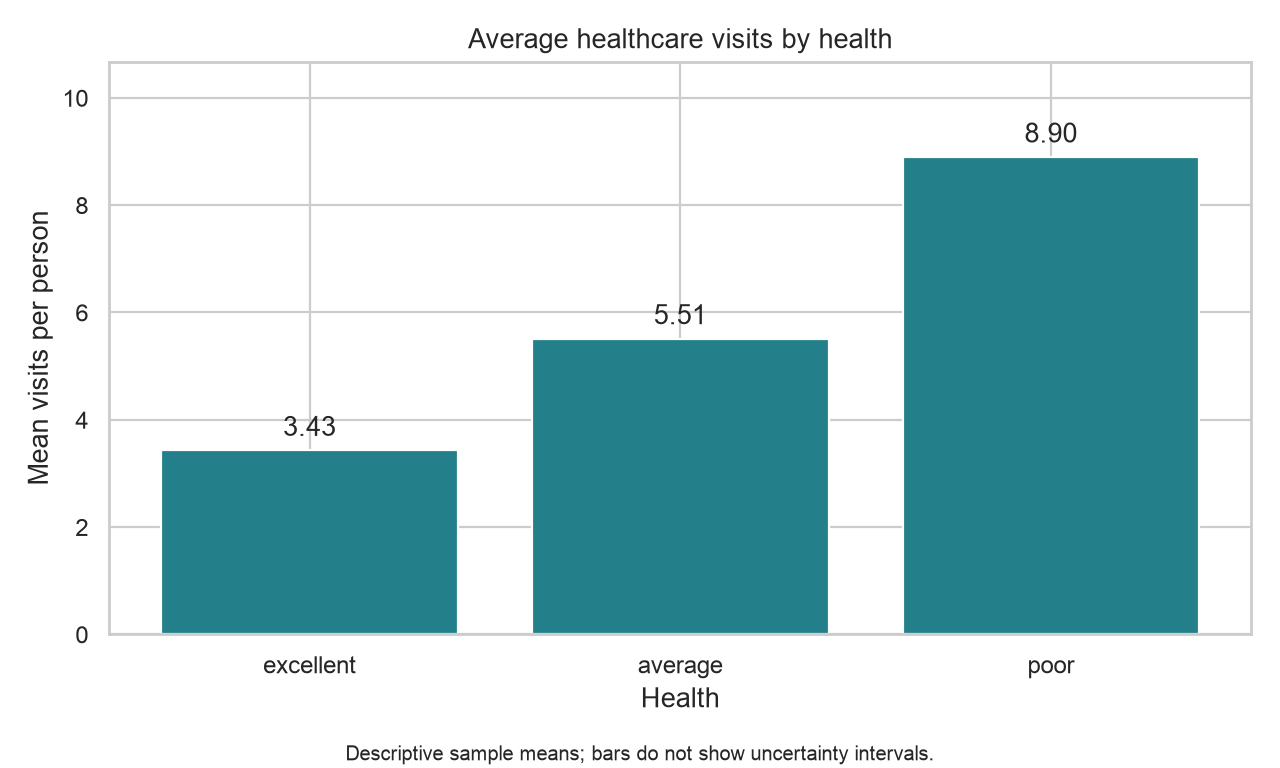

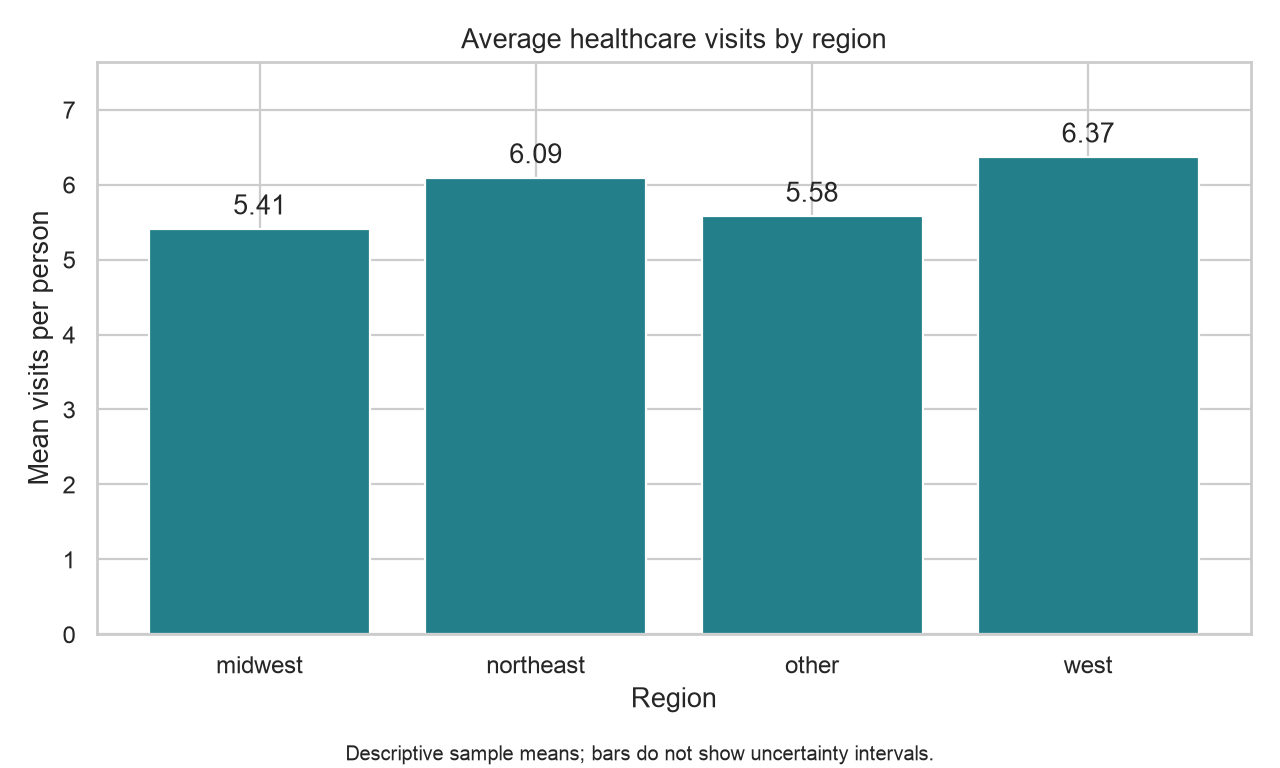

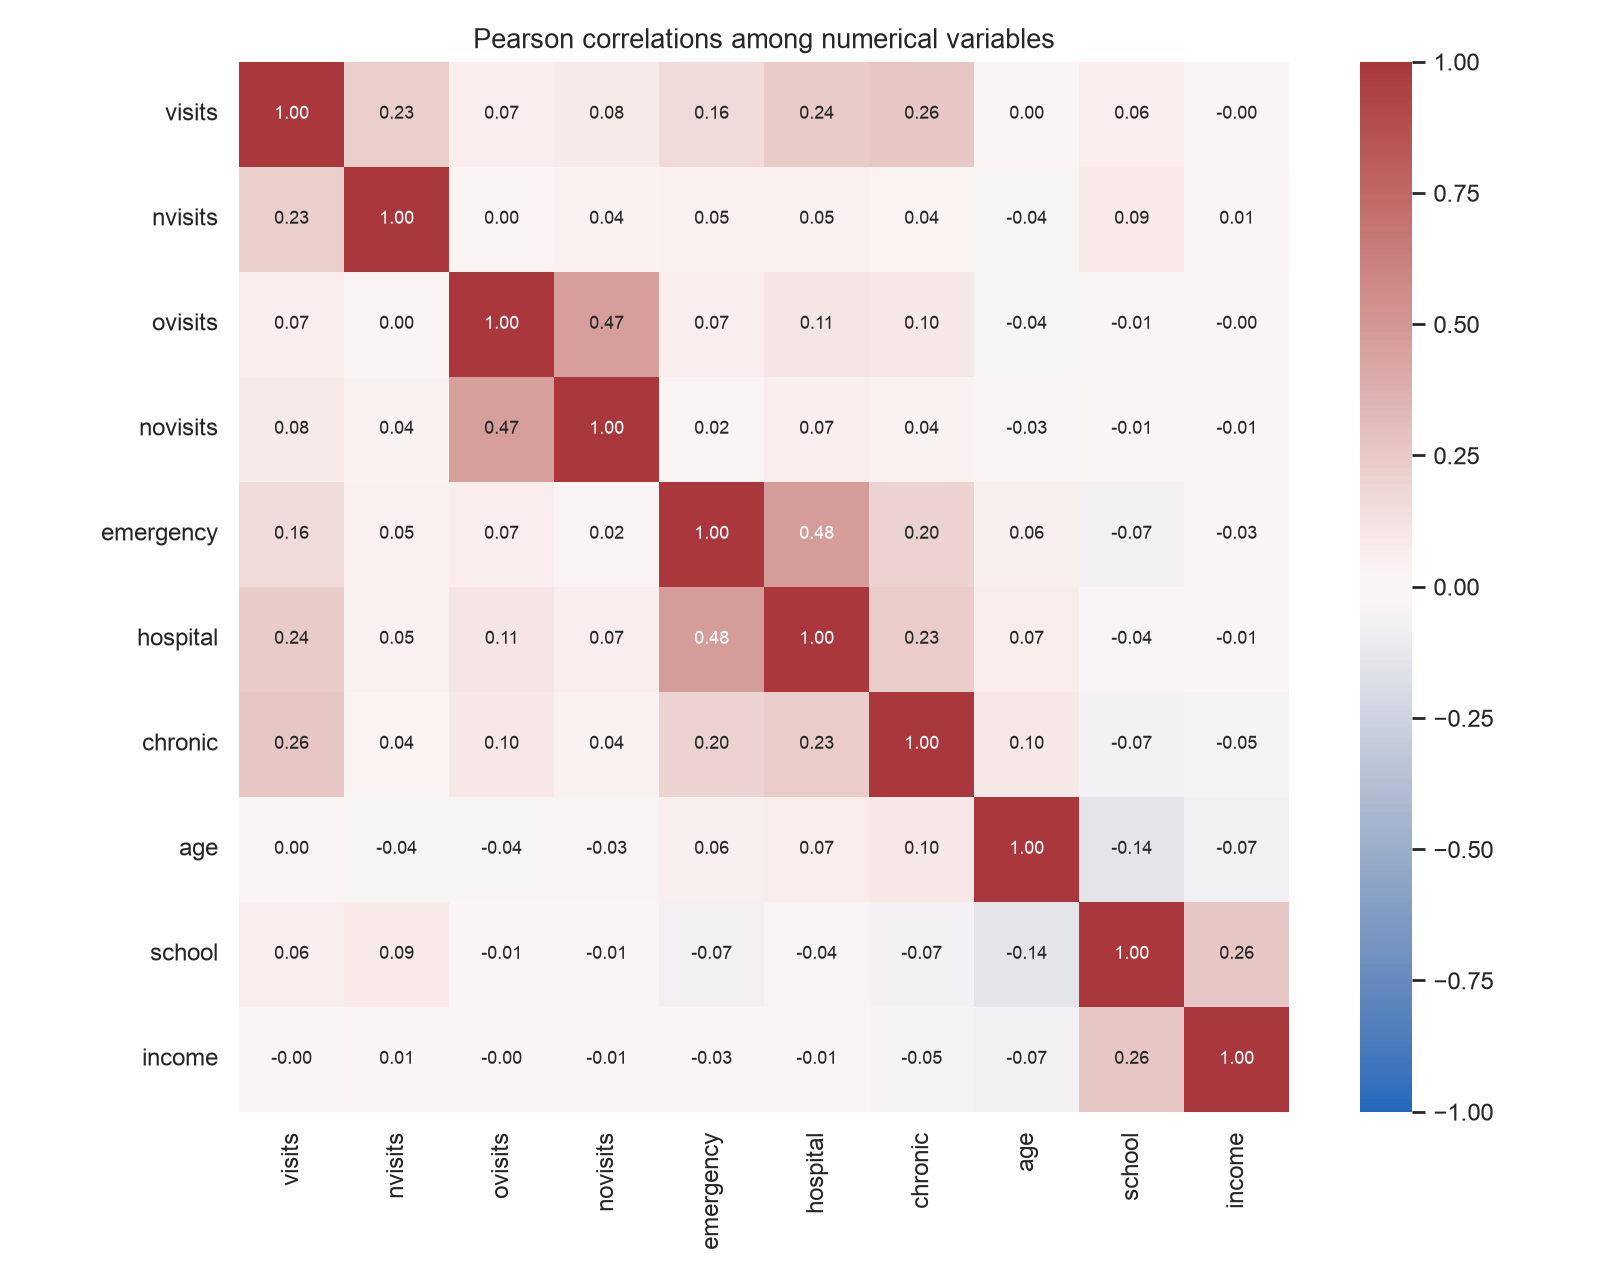

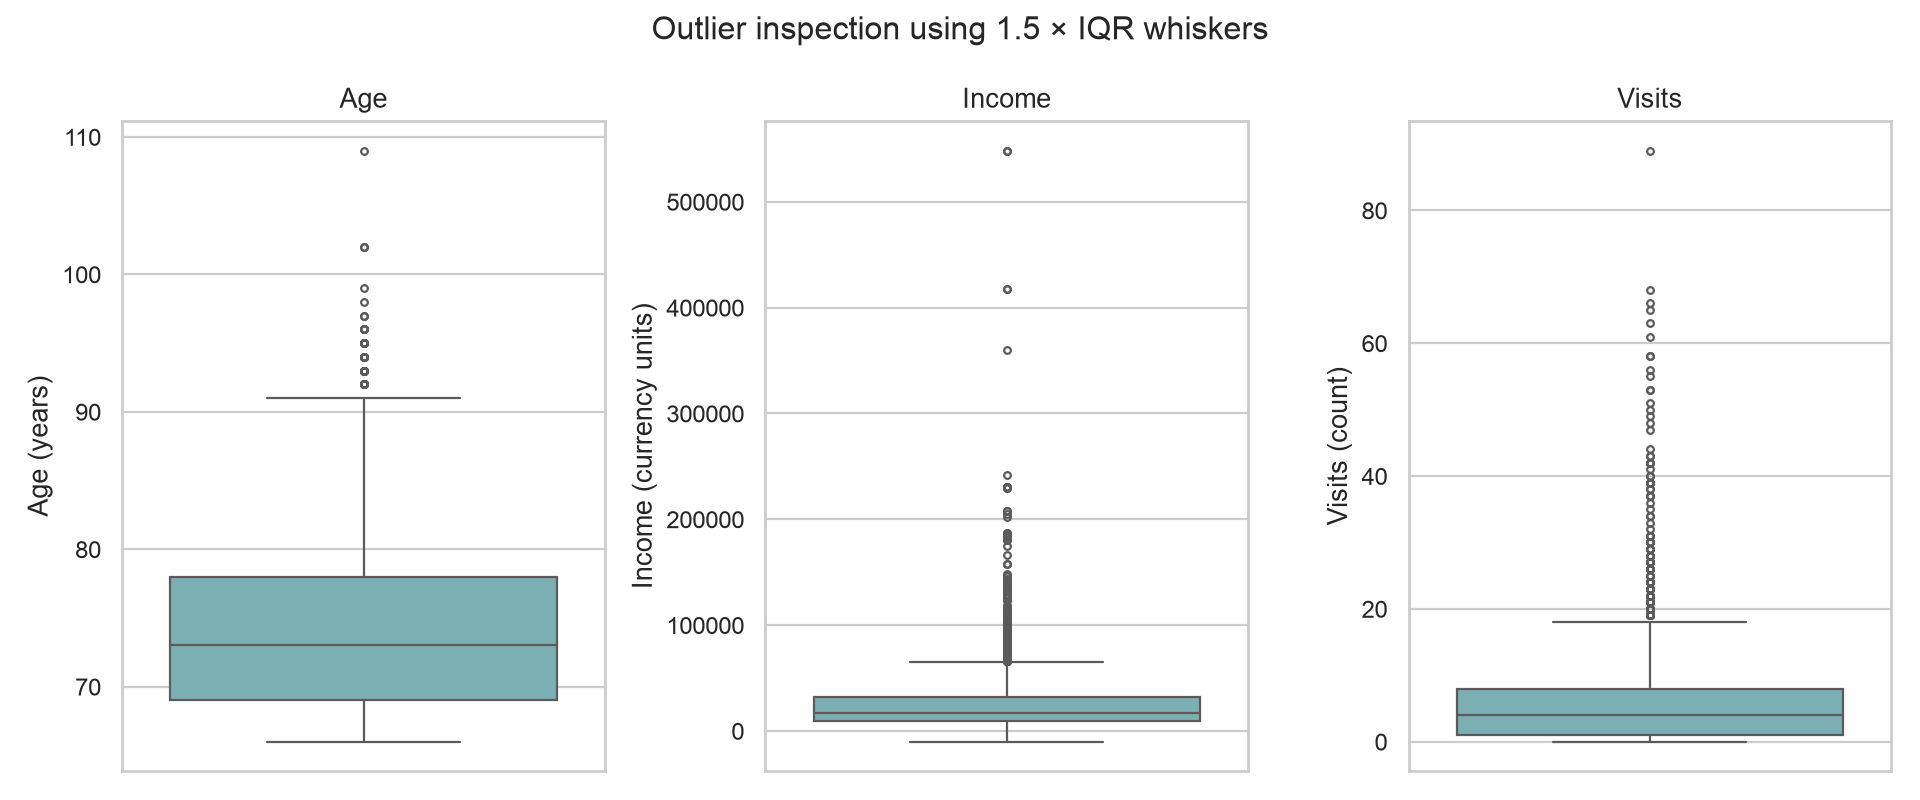

In [5]:
sns.set_theme(style='whitegrid', context='notebook')
for group, order in [('health',['excellent','average','poor']), ('region',sorted(processed.region.unique()))]:
    values = summaries[group].reindex(order)
    fig, ax = plt.subplots(figsize=(8,4.8))
    bars = ax.bar(values.index.astype(str), values['mean'], color='#237f89')
    ax.bar_label(bars, labels=[f'{x:.2f}' for x in values['mean']], padding=4)
    ax.set(title=f'Average healthcare visits by {group}', xlabel=group.title(), ylabel='Mean visits per person')
    ax.set_ylim(0, values['mean'].max()*1.2)
    fig.text(.5,.01,'Descriptive sample means; bars do not show uncertainty intervals.',ha='center',fontsize=9)
    fig.tight_layout(rect=[0,.035,1,1])
    fig.savefig(f'plots/mean_visits_by_{group}.png', dpi=160)
    plt.close(fig)
corr = processed[numerical_cols].corr()
corr.to_csv('tables/numerical_correlations.csv')
fig, ax = plt.subplots(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, center=0, square=True, ax=ax, annot_kws={'size':8})
ax.set_title('Pearson correlations among numerical variables')
fig.tight_layout()
fig.savefig('plots/correlation_heatmap.png', dpi=160)
plt.close(fig)
fig, axes = plt.subplots(1,3,figsize=(12,5))
outliers = []
for ax, col, label in zip(axes, key, ['Age (years)','Income (currency units)','Visits (count)']):
    sns.boxplot(y=processed[col], ax=ax, color='#72b7bc', flierprops={'markersize':3})
    ax.set(title=col.title(), ylabel=label)
    q1,q3 = processed[col].quantile([.25,.75])
    iqr = q3-q1
    lo,hi = q1-1.5*iqr,q3+1.5*iqr
    outliers.append({'variable':col,'lower_fence':lo,'upper_fence':hi,'flagged_records':int(((processed[col]<lo)|(processed[col]>hi)).sum())})
fig.suptitle('Outlier inspection using 1.5 × IQR whiskers')
fig.tight_layout()
fig.savefig('plots/boxplots.png', dpi=160)
plt.close(fig)
outlier_table = pd.DataFrame(outliers)
print(outlier_table.to_string(index=False))
outlier_table.to_csv('tables/outlier_summary.csv', index=False)


## Findings and recommendations

**Data quality.** All 4,406 records were retained. The file has no missing values or duplicates. There are 3 negative-income records; these need source clarification before any decision to recode them. In-memory optimization reduced storage from 2,263,919 to 159,767 bytes.

**Age and income.** After conversion, mean age is 74.02 years, the median is 73.0, and the range is 66–109. This older sample cannot represent all age groups. Mean income is 25,271.32 currency units versus a median of 16,981.50; the upper tail pulls the mean upward. Income ranges from -10,125.00 to 548,351.00.

**Visits.** Mean visits is 5.77, median visits is 4, and the maximum is 89. There are 683 zero-visit records (15.5%). The mean exceeding the median and the upper box-plot tail indicate right skew.

**Health.** Average visits are 8.90 for poor health (n=554), 5.51 for average health (n=3509), and 3.43 for excellent health (n=343). Poor-health respondents have the highest descriptive utilization. Aura could investigate their service needs when planning care capacity; this association does not prove that health status causes the difference.

**Region.** Mean visits are highest in west (6.37) and lowest in midwest (5.41), a gap of 0.96 visits per person. The source category `other` is retained as given. Differences are unadjusted for age, health, and other case-mix factors and have not been tested for statistical significance. Investigate these factors before allocating resources by region.

**Correlation and outliers.** Visits and chronic-condition count have a Pearson correlation of 0.262. Correlations describe linear associations and may be affected by skew and extreme observations. The 1.5 × IQR rule flags 53 age, 270 income, and 173 visit observations. A statistical flag is not evidence of a data error. Review source records and consider sensitivity analyses before removing values.

**Limits.** This analysis uses unweighted sample summaries. The supplied CSV does not establish survey weights, a sampling design, precise visit definitions or reporting periods, or income currency/price basis. Avoid interpreting `visits` as all types of healthcare use combined: the file has other distinct utilization columns. Historical data should not be treated as a current forecast. The analysis supports further investigation rather than clinical decisions or causal conclusions.


In [6]:
# Verify exported files, transformations, and preservation of records.
for filename in ['NSMES1988new.csv','NSMES1988updated.csv','NSMES1988_Dummy.csv']:
    exported = pd.read_csv(filename)
    assert len(exported) == len(raw)
    assert exported['record_id'].is_unique
    assert not exported.columns.str.startswith('Unnamed:').any()
reloaded = pd.read_csv('NSMES1988updated.csv')
assert np.allclose(reloaded.age, raw.age*10)
assert np.allclose(reloaded.income, raw.income*10000)
assert np.array_equal(reloaded.visits, raw.visits)
print('Verification passed: all three CSV exports preserve 4,406 records and required transformations.')


Verification passed: all three CSV exports preserve 4,406 records and required transformations.


## Reproduce the project
Install `pandas`, `numpy`, `matplotlib`, and `seaborn`. Open this notebook in Jupyter or Google Colab, place/upload the original CSV in the working directory, and run all cells in order. Alternatively run `python aura_capstone.py` from this folder. The saved notebook already contains executed outputs and plots. The HTML copy can be opened without Python.